# Sensitivities

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib notebook

In [8]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.ticker import MultipleLocator
# from PyAstronomy import pyasl
from astropy import units as u
from astropy import constants as c
from astropy.coordinates import SkyCoord
# from tqdm import tqdm
from pathlib import Path
# PlatoSim libraries
import platosim.plot      as pt
import platosim.utilities as ut
from platosim.matplotlibrc import setup_notebook
setup_notebook()
# Adjust notebook
from IPython.display import display, HTML
display(HTML("<style>.container {width:70% !important; }</style>"))
# Random generator
seed = 123456789
rng = ut.rng(seed)

In [4]:
# Paths to where data is stored
hdir = ut.getHomeDir('inputfiles/data_picsim')
path = ut.getWorkDir('moonwalk')
idir = path / 'input'
fdir = Path('/lhome/nicholas/Nextcloud/latex/papers/2027_Moonwalk/figures')

---
## Define Solar System parameters
---

In [5]:
# Radii [km]
R_sun      = 695_700
R_Jupiter  = 71_492
R_Saturn   = 58_232
R_Uranus   = 25_362
R_Neptune  = 24_622
R_Earth    = 6_371
R_Mars     = 3_390
# Jupiters moons
R_Ganymede = 2631.2
R_Callisto = 2410.3
R_Io       = 1821.5
R_Europa   = 1560.8
# Saturn's moons
R_Titan     = 2575
R_Rhea      = 765
R_Dione     = 560
R_Tethys    = 530
R_Enceladus = 250
R_Mimas     = 196
# Uranus' moons
R_Titania  = 789
R_Oberon   = 760
R_Umbriel  = 585
R_Ariel    = 580
R_Miranda  = 235
# Neptune's moons
R_Triton  = 1353.4
R_Proteus = 210
R_Nep = np.array([R_Triton, R_Proteus])
# Combine all
R_Jup = np.array([R_Ganymede, R_Callisto, R_Io, R_Europa])
R_Sat = np.array([R_Titan, R_Rhea, R_Dione, R_Tethys, R_Enceladus, R_Mimas])
R_Ura = np.array([R_Titania, R_Oberon, R_Umbriel, R_Ariel, R_Miranda])
R_Nep = np.array([R_Triton, R_Proteus])
R_moons = np.concatenate([R_Jup, R_Sat, R_Ura, R_Nep])

In [6]:
# Semi-major axes of all moon above 100 km
# Jupiter's moons
a_Ganymede  = 1_070_400
a_Callisto  = 1_882_700
a_Io        = 421_800
a_Europa    = 671_100
# Saturn's moons
a_Titan     = 1_221_950
a_Rhea      = 527_108
a_Dione     = 377_396
a_Tethys    = 294_619
a_Enceladus = 237_948
a_Mimas     = 185_539
# Uranus' moons
a_Titania  = 129_858
a_Oberon   = 583_449
a_Umbriel  = 265_982
a_Ariel    = 190_930 
a_Miranda  = 129_858
# Neptune's moons
a_Triton  = 354_760 # Irregular
a_Proteus = 117_647
# Combine all
a_Jup = np.array([a_Ganymede, a_Callisto, a_Io, a_Europa]) / R_Jupiter
a_Sat = np.array([a_Titan, a_Rhea, a_Dione, a_Tethys, a_Enceladus, a_Mimas]) / R_Saturn
a_Ura = np.array([a_Titania, a_Oberon, a_Umbriel, a_Ariel, a_Miranda]) / R_Uranus
a_Nep = np.array([a_Triton, a_Proteus]) / R_Neptune
a_moons = np.concatenate([a_Jup, a_Sat, a_Ura, a_Nep])

---
## Transit sensitivities
---

In [9]:
def transit_depth(R_moon, R_star=R_sun):
    """Calculate transit depths [ppm]
    """
    return (R_moon / R_star)**2 * 1e6

def noise(mag, ncam, rms=0.04, tdur=3600, passband='P', camtype='normal'):
    """Three rocket noise model of PLATO
    """
    noise_jitter     = ut.getJitterNoiseLimitNSR(rms, tdur=tdur, camType=camtype)
    noise_photon     = ut.getPhotonNoiseLimitNSR(mag, passband, ncam=ncam)
    noise_background = ut.getBackgroundNoiseLimitNSR(mag, passband, ncam=ncam)
    return np.sqrt(noise_jitter**2 + noise_photon**2 + noise_background**2)

def snr_transit(N, depth, noise):
    """Detection efficiency (Cabrera+2026, Eq.9)
    """
    return np.sqrt(N) * depth / noise

<IPython.core.display.Javascript object>


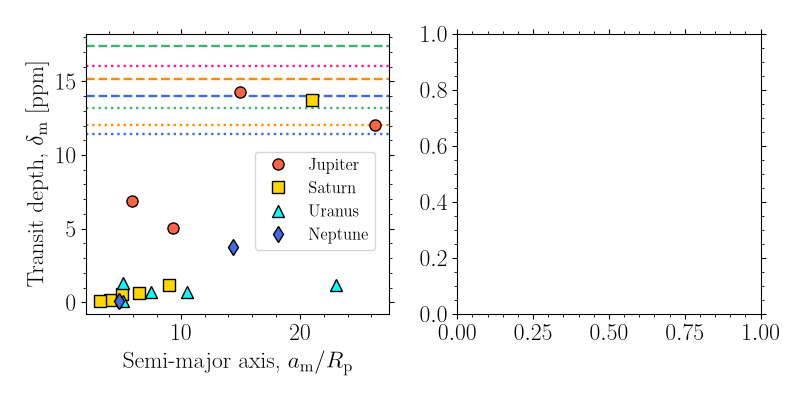

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
aa, ms, lw = 1, 8, 1.7
mk = ['o', 's', '^', 'd']

# Plot of a_moon vs. depth_moon
cc = ['royalblue', 'darkorange', 'mediumseagreen', 'deeppink']
ax[0].axhline(y=noise(8, 24), c=cc[0], lw=lw, ls='--')
ax[0].axhline(y=noise(7, 24), c=cc[0], lw=lw, ls=':')
ax[0].axhline(y=noise(8, 18), c=cc[1], lw=lw, ls='--')
ax[0].axhline(y=noise(7, 18), c=cc[1], lw=lw, ls=':')
ax[0].axhline(y=noise(8, 12), c=cc[2], lw=lw, ls='--')
ax[0].axhline(y=noise(7, 12), c=cc[2], lw=lw, ls=':')
ax[0].axhline(y=noise(7,  6), c=cc[3], lw=lw, ls=':')
cc = ['tomato', 'gold', 'cyan', 'royalblue']
ax[0].plot(a_Jup, transit_depth(R_Jup), mk[0], ms=ms, mec='k', alpha=aa, c=cc[0], label='Jupiter')
ax[0].plot(a_Sat, transit_depth(R_Sat), mk[1], ms=ms, mec='k', alpha=aa, c=cc[1], label='Saturn')
ax[0].plot(a_Ura, transit_depth(R_Ura), mk[2], ms=ms, mec='k', alpha=aa, c=cc[2], label='Uranus')
ax[0].plot(a_Nep, transit_depth(R_Nep), mk[3], ms=ms, mec='k', alpha=aa, c=cc[3], label='Neptune')
# Labels
ax[0].set_xlabel(r'Semi-major axis, $a_{\rm m}/R_{\rm p}$')
ax[0].set_ylabel(r'Transit depth, $\delta_{\rm m}$ [ppm]')
ax[0].legend(fontsize=12, bbox_to_anchor=(0.53, 0.2, 0.5, 0.5))
plt.tight_layout();
# fig.savefig(fdir / 'prediction_solar.png', bbox_inches='tight', dpi=200)

### Transit Detection Efficiency (TDE)

<IPython.core.display.Javascript object>


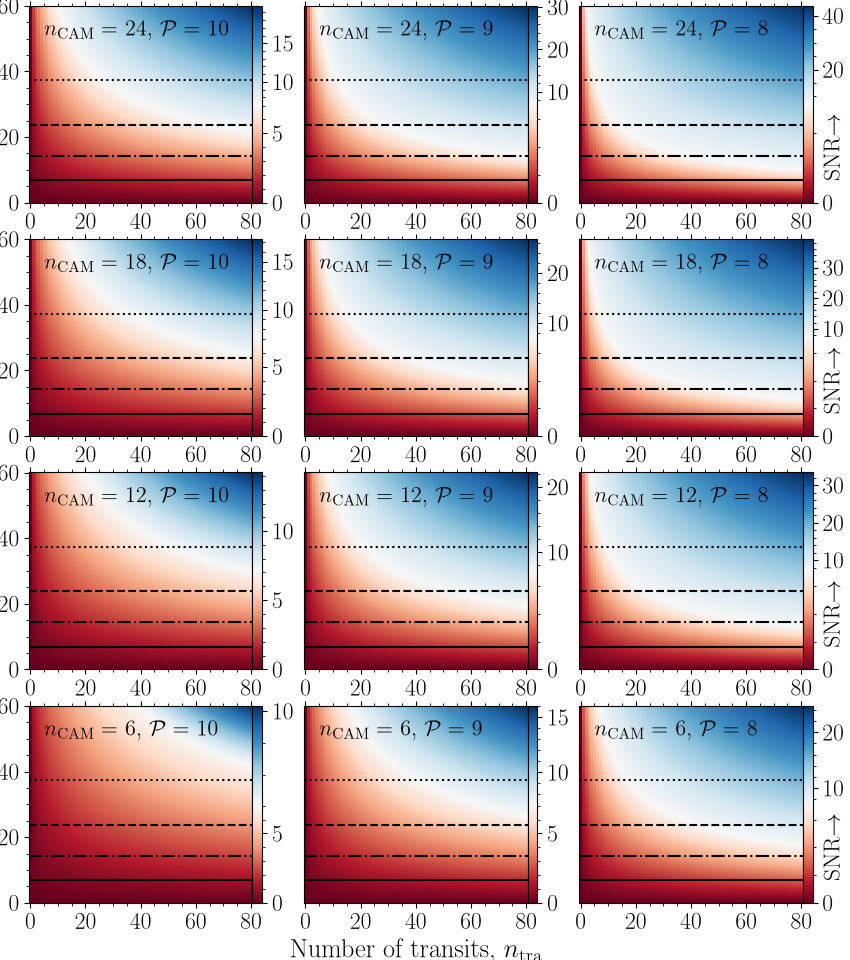

In [35]:
n_grid = 1000
delta_max = 60
ntran_max = 80
delta = np.linspace(0, delta_max, 1000)
ntran = np.linspace(0, ntran_max, ntran_max)
ncams = [24, 18, 12, 6]
snr = 7.1
J,I = 4,3
fs = 19
# Plotting
fig, ax = plt.subplots(J, I, figsize=(8.5, 2.4*J))
for j in range(4):
    ncam = ncams[j]
    for i in range(3):
        # Handle tick labels
        ax[j,i].xaxis.set_major_locator(MultipleLocator(20))
        ax[j,i].yaxis.set_major_locator(MultipleLocator(20))
        if i > 0:
            ax[j,i].set_yticks([])            
        # Plot each planel
        mag = 10-i
        sigma = noise(mag, ncam, tdur=3600)
        xx, yy = np.meshgrid(ntran, delta)
        zz = np.sqrt(xx) * yy / sigma
        divnorm = colors.TwoSlopeNorm(vmin=zz.min(), vcenter=snr, vmax=zz.max())
        im = ax[j, i].pcolormesh(xx, yy, zz, cmap='RdBu', norm=divnorm)
        cbar = plt.colorbar(im, pad=0)
        ax[j,i].text(5, delta_max*0.85, r'$n_{\rm CAM}=$ '+f'{ncam}, '+r'$\mathcal{P}=$'+f' {mag}', fontsize=16)
        if i == 2:
            ax[j,i].text(88, 8, r'SNR$\rightarrow$', rotation='vertical')
        # Plot hlines for Galilean moons
        R = np.array([2/3*R_Earth, R_Mars, R_Ganymede, R_Io])
        ls = [':', '--', '-.', '-']
        for r,l in zip(R,ls): 
            ax[j,i].axhline(y=transit_depth(r), c='k', lw=1.5, ls=l)
# Common settings        
ax[j,1].set_xlabel(r'Number of transits, $n_{\rm tra}$', fontsize=fs)
fig.text(-0.04, 0.5, r'Transit depth, $\delta$', va='center', rotation='vertical', fontsize=fs)
plt.tight_layout(pad=-0.1);
fig.savefig(fdir / 'prediction_TDE.png', bbox_inches='tight', dpi=200)

<IPython.core.display.Javascript object>


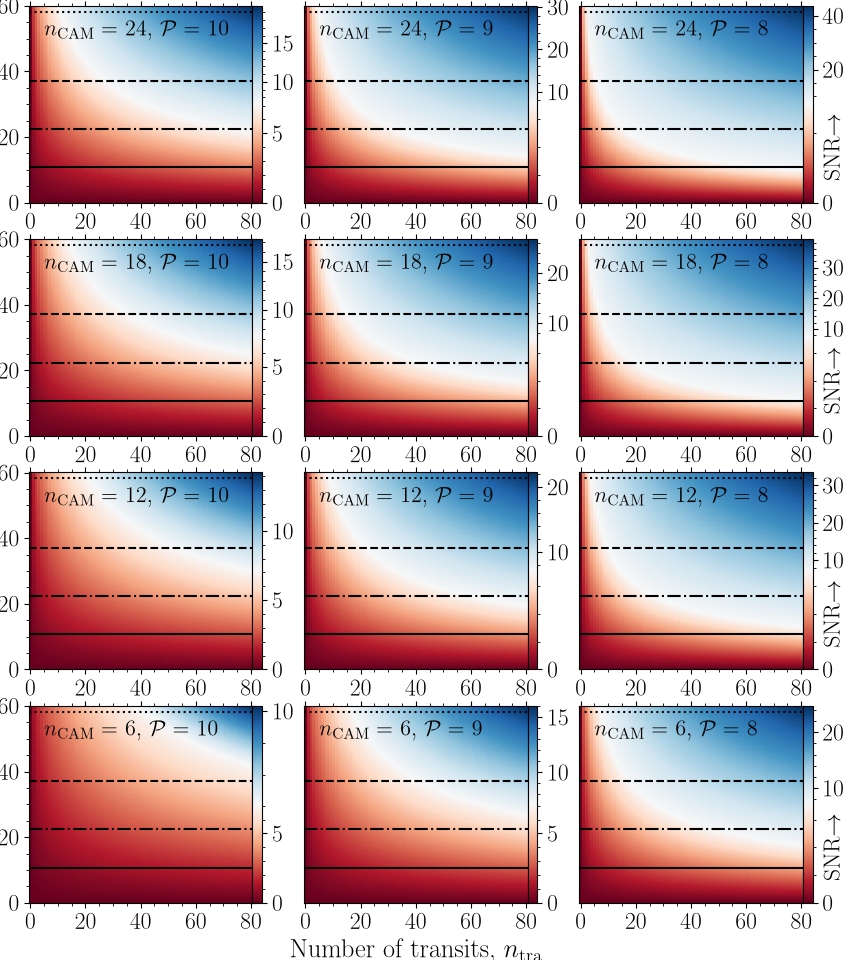

In [42]:
n_grid = 1000
delta_max = 60
ntran_max = 80
delta = np.linspace(0, delta_max, 1000)
ntran = np.linspace(0, ntran_max, ntran_max)
ncams = [24, 18, 12, 6]
snr = 7.1
J,I = 4,3
fs = 19
# Plotting
fig, ax = plt.subplots(J, I, figsize=(8.5, 2.4*J))
for j in range(4):
    ncam = ncams[j]
    for i in range(3):
        # Handle tick labels
        ax[j,i].xaxis.set_major_locator(MultipleLocator(20))
        ax[j,i].yaxis.set_major_locator(MultipleLocator(20))
        if i > 0:
            ax[j,i].set_yticks([])            
        # Plot each planel
        mag = 10-i
        sigma = noise(mag, ncam, tdur=3600)
        xx, yy = np.meshgrid(ntran, delta)
        zz = np.sqrt(xx) * yy / sigma
        divnorm = colors.TwoSlopeNorm(vmin=zz.min(), vcenter=snr, vmax=zz.max())
        im = ax[j, i].pcolormesh(xx, yy, zz, cmap='RdBu', norm=divnorm)
        cbar = plt.colorbar(im, pad=0)
        ax[j,i].text(5, delta_max*0.85, r'$n_{\rm CAM}=$ '+f'{ncam}, '+r'$\mathcal{P}=$'+f' {mag}', fontsize=16)
        if i == 2:
            ax[j,i].text(88, 8, r'SNR$\rightarrow$', rotation='vertical')
        # Plot hlines for Galilean moons
        R = np.array([2/3*R_Earth, R_Mars, R_Ganymede, R_Io])
        ls = [':', '--', '-.', '-']
        for r,l in zip(R,ls): 
            ax[j,i].axhline(y=transit_depth(r, R_star=0.8*R_sun), c='k', lw=1.5, ls=l)
# Common settings        
ax[j,1].set_xlabel(r'Number of transits, $n_{\rm tra}$', fontsize=fs)
fig.text(-0.04, 0.5, r'Transit depth, $\delta$', va='center', rotation='vertical', fontsize=fs)
plt.tight_layout(pad=-0.1);
# fig.savefig(fdir / 'prediction_TDE.png', bbox_inches='tight', dpi=200)